# Programación semanal iterativa de rutas y descargas

## 1. Modelo matemático y lógica de solución

**Objetivo.** Asignar las rutas flexibles a días de la semana, secuenciar las rutas de cada vehículo y programar su descarga en **tres bahías compartidas**. Cada ruta se ejecuta exactamente una vez y siempre con su vehículo original. Las rutas fijas conservan su día. Las duraciones ya incluyen el retorno al centro de descarga.

**Variables por ruta $i$:** 
- $x_i$ inicio de ruta; 
- $a_i=x_i+t_i$ llegada al centro; 
- $s_i$ inicio de descarga; 
- $f_i=s_i+p$ fin de descarga; 
- $w_i=s_i-a_i\geq0$ espera en cola. 
- $z_{im}$ indica bahía asignada y las binarias de precedencia ordenan rutas y descargas. 

**Por vehículo y día:** 
- $e_{vd}\geq0$ mide minutos posteriores al fin de jornada. 
- el inicio de la primera ruta de cada vehículo que opera ese día se fija a las 07:00 (mediante restricción de mínimo inicio).
- entre rutas hay un intervalo mínimo $\tau$ que sería un tiempo ocioso.

**Objetivo diario ponderado:**
$$\min\ Z_d=\alpha\sum_{i\in J_d}w_i+\beta\sum_{v\in V}e_{vd}$$
El algoritmo semanal busca minimizar $Z(S)=\sum_d Z_d(S)$, con $S$ la asignación de rutas a días. 
Se reportan **por separado** espera total, horas extra y ocio adicional entre rutas; este último no se penaliza en esta versión. 
La jornada deja de ser una restricción dura: $f_i\le H^{fin}+e_{vd}$, opcionalmente $e_{vd}\le E^{max}$.

**Restricciones esenciales:** 
- cada descarga usa exactamente una bahía; 
- no hay solapamiento en la misma bahía; 
- las rutas del mismo vehículo no se solapan y entre descarga y siguiente salida transcurren al menos $\tau$; 
- cada ruta fija conserva su día; 
- una flexible puede cambiar de día **solo dentro de los días permitidos**; 
- las descargas se planifican anticipadamente; **no se impone FIFO estricto**.

### Algoritmo híbrido VNS + MILP diario

1. Construir una configuración inicial semanal (datos **aleatorios** o **manuales**).
2. Resolver el MILP de cada día y registrar tiempos de cola, extraordinarios y ocio.
3. Generar un vecino mediante **mover**, **intercambiar** o **reorganizar** rutas flexibles del mismo vehículo.
4. Reoptimizar **únicamente los días modificados**, reutilizando resultados de los demás días.
5. Conservar la mejor solución y detenerse al llegar al máximo de iteraciones o al límite de iteraciones sin mejora.

Si el MILP diario alcanza el límite de tiempo, se acepta solo una solución factible disponible y se identifica su estado. 
Una asignación que supere la jornada **no se descarta**, se mide el tiempo extraordinario.


## 2. Configuración inicial editable

Seleccionar `MODO_DATOS = "manual"` o `"aleatorio"`.

**Modo manual:** para editar por separado `RUTAS_FIJAS` y `RUTAS_FLEXIBLES`. Cada duración representa una ruta; **no existe una proporción obligatoria entre fijas y flexibles**. Las rutas fijas se indican por vehículo y día. Cada flexible tiene su propio identificador, duración, día inicial y días permitidos.

**Modo aleatorio:** para modificar `FIJAS_POR_DIA`, `FLEXIBLES_POR_VEHICULO` y los rangos de duración. Los números de rutas también pueden ser distintos por vehículo o día.

**Importante:** las duraciones incluyen el regreso al centro de descarga; no incluyen los 20 minutos de descarga. El modelo admite tiempo extraordinario y lo penaliza. La factibilidad final depende de la optimización diaria de todos los vehículos y bahías, no solo de la suma de duraciones.

In [18]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from itertools import combinations
from scipy.optimize import milp, Bounds, LinearConstraint
from scipy.sparse import lil_matrix
from IPython.display import display

DIAS = ["Lunes", "Martes", "Miércoles", "Jueves", "Viernes"]
VEHICULOS = [f"V{i:02d}" for i in range(1, 5)]
MODO_DATOS = "manual"  # Opciones: "manual" o "aleatorio"
SEMILLA = 20261018

HORA_INICIO = 7 * 60   # Minutos absolutos desde medianoche
HORA_FIN = 15 * 60
DURACION_DESCARGA = 20
INTERVALO_MINIMO = 10.0
BAHIAS = 3
MAX_EXTRA = 120        # Opciones: 120 minutos; None para no fijar límite operativo de horas extra
ALPHA = 1.0            # Peso por minuto de cola
BETA = 1.0             # Peso por minuto extraordinario
MAX_ITERACIONES = 100  # Aumentar para búsqueda más profunda
MAX_SIN_MEJORA = 5
TIEMPO_MILP = 10        # Segundos por día/candidato
BIG_M = 2000

# ================================================================
# CONFIGURACIÓN MANUAL: modifique las listas de forma independiente
# ================================================================
# Cada elemento de una lista es la duración de UNA ruta fija.
# Se pueden indicar 0, 1, 2 o más rutas fijas por día.
RUTAS_FIJAS = {
    "V01": {
        "Lunes": [188], "Martes": [205], "Miércoles": [174], "Jueves": [201], "Viernes": [190],
    },
    "V02": {
        "Lunes": [199], "Martes": [184], "Miércoles": [211], "Jueves": [187], "Viernes": [195],
    },
    "V03": {
        "Lunes": [177], "Martes": [200], "Miércoles": [192], "Jueves": [216], "Viernes": [185],
    },
    "V04": {
        "Lunes": [210], "Martes": [193], "Miércoles": [179], "Jueves": [206], "Viernes": [197],
    },
}

# Cada elemento representa UNA ruta flexible; agregue tantos como necesite.
# Los días permitidos pueden variar de una ruta a otra.
RUTAS_FLEXIBLES = {
    "V01": [
        {"ruta": "V01-L01", "duracion": 196, "dia_inicial": "Lunes", "dias_permitidos": DIAS.copy()},
        {"ruta": "V01-L02", "duracion": 178, "dia_inicial": "Martes", "dias_permitidos": DIAS.copy()},
        {"ruta": "V01-L03", "duracion": 218, "dia_inicial": "Miércoles", "dias_permitidos": DIAS.copy()},
        {"ruta": "V01-L04", "duracion": 183, "dia_inicial": "Jueves", "dias_permitidos": DIAS.copy()},
        {"ruta": "V01-L05", "duracion": 202, "dia_inicial": "Viernes", "dias_permitidos": DIAS.copy()},
    ],
    "V02": [
        {"ruta": "V02-L01", "duracion": 180, "dia_inicial": "Lunes", "dias_permitidos": DIAS.copy()},
        {"ruta": "V02-L02", "duracion": 213, "dia_inicial": "Martes", "dias_permitidos": DIAS.copy()},
        {"ruta": "V02-L03", "duracion": 176, "dia_inicial": "Miércoles", "dias_permitidos": DIAS.copy()},
        {"ruta": "V02-L04", "duracion": 207, "dia_inicial": "Jueves", "dias_permitidos": DIAS.copy()},
        {"ruta": "V02-L05", "duracion": 190, "dia_inicial": "Viernes", "dias_permitidos": DIAS.copy()},
    ],
    "V03": [
        {"ruta": "V03-L01", "duracion": 220, "dia_inicial": "Lunes", "dias_permitidos": DIAS.copy()},
        {"ruta": "V03-L02", "duracion": 189, "dia_inicial": "Martes", "dias_permitidos": DIAS.copy()},
        {"ruta": "V03-L03", "duracion": 198, "dia_inicial": "Miércoles", "dias_permitidos": DIAS.copy()},
        {"ruta": "V03-L04", "duracion": 181, "dia_inicial": "Jueves", "dias_permitidos": DIAS.copy()},
        {"ruta": "V03-L05", "duracion": 204, "dia_inicial": "Viernes", "dias_permitidos": DIAS.copy()},
    ],
    "V04": [
        {"ruta": "V04-L01", "duracion": 181, "dia_inicial": "Lunes", "dias_permitidos": DIAS.copy()},
        {"ruta": "V04-L02", "duracion": 202, "dia_inicial": "Martes", "dias_permitidos": DIAS.copy()},
        {"ruta": "V04-L03", "duracion": 217, "dia_inicial": "Miércoles", "dias_permitidos": DIAS.copy()},
        {"ruta": "V04-L04", "duracion": 187, "dia_inicial": "Jueves", "dias_permitidos": DIAS.copy()},
        {"ruta": "V04-L05", "duracion": 191, "dia_inicial": "Viernes", "dias_permitidos": DIAS.copy()},
    ],
}

# ================================================================
# CONFIGURACIÓN ALEATORIA: cantidades y duraciones independientes
# ================================================================
FIJAS_POR_DIA = 1               # Entero o diccionario {vehiculo: {dia: cantidad}}
FLEXIBLES_POR_VEHICULO = 5       # Entero o diccionario {vehiculo: cantidad}
RANGO_DURACION_FIJA = (170, 220)
RANGO_DURACION_FLEXIBLE = (170, 220)


def _cantidad_fija(vehiculo, dia):
    if isinstance(FIJAS_POR_DIA, dict):
        valor = FIJAS_POR_DIA.get(vehiculo, 0)
        return int(valor.get(dia, 0) if isinstance(valor, dict) else valor)
    return int(FIJAS_POR_DIA)


def _cantidad_flexible(vehiculo):
    if isinstance(FLEXIBLES_POR_VEHICULO, dict):
        return int(FLEXIBLES_POR_VEHICULO.get(vehiculo, 0))
    return int(FLEXIBLES_POR_VEHICULO)


def crear_datos(modo=MODO_DATOS, semilla=SEMILLA):
    rng = np.random.default_rng(semilla)
    registros = []

    if modo == "manual":
        # Convertimos cada duración fija en una ruta con ID único y día inamovible.
        for vehiculo, por_dia in RUTAS_FIJAS.items():
            for dia, duraciones in por_dia.items():
                for numero, duracion in enumerate(duraciones, start=1):
                    registros.append(dict(
                        vehiculo=vehiculo, ruta=f"{vehiculo}-F{numero:02d}-D{DIAS.index(dia)+1:02d}",
                        dia=dia, tipo="Fija", duracion=int(duracion),
                        dias_permitidos=[dia]))

        # Las flexibles tienen su propia ventana de días y siempre conservan su vehículo.
        for vehiculo, rutas in RUTAS_FLEXIBLES.items():
            for numero, ruta in enumerate(rutas, start=1):
                registros.append(dict(
                    vehiculo=vehiculo, ruta=ruta.get("ruta", f"{vehiculo}-L{numero:03d}"),
                    dia=ruta["dia_inicial"], tipo="Flexible",
                    duracion=int(ruta["duracion"]),
                    dias_permitidos=list(ruta["dias_permitidos"])))

    elif modo == "aleatorio":
        for vehiculo in VEHICULOS:
            for dia in DIAS:
                for numero in range(1, _cantidad_fija(vehiculo, dia) + 1):
                    registros.append(dict(
                        vehiculo=vehiculo, ruta=f"{vehiculo}-F-{DIAS.index(dia)+1:02d}-{numero:02d}",
                        dia=dia, tipo="Fija",
                        duracion=int(rng.integers(*[RANGO_DURACION_FIJA[0], RANGO_DURACION_FIJA[1]+1])),
                        dias_permitidos=[dia]))

            # Distribución inicial equilibrada; la búsqueda puede mover estas rutas.
            for numero in range(1, _cantidad_flexible(vehiculo) + 1):
                dia = DIAS[(numero - 1) % len(DIAS)]
                registros.append(dict(
                    vehiculo=vehiculo, ruta=f"{vehiculo}-L{numero:03d}",
                    dia=dia, tipo="Flexible",
                    duracion=int(rng.integers(RANGO_DURACION_FLEXIBLE[0], RANGO_DURACION_FLEXIBLE[1]+1)),
                    dias_permitidos=DIAS.copy()))
    else:
        raise ValueError("MODO_DATOS debe ser 'manual' o 'aleatorio'")

    datos = pd.DataFrame(registros, columns=["vehiculo", "ruta", "dia", "tipo", "duracion", "dias_permitidos"])
    if datos.empty:
        raise ValueError("Debe configurarse al menos una ruta")
    if not datos.ruta.is_unique:
        raise ValueError("Los identificadores de ruta deben ser únicos")
    if not datos.duracion.gt(0).all():
        raise ValueError("Todas las duraciones deben ser positivas")
    if not datos.dia.isin(DIAS).all():
        raise ValueError("Se encontró un día inicial fuera de DIAS")
    if not datos.apply(lambda r: bool(r.dias_permitidos) and all(d in DIAS for d in r.dias_permitidos) and r.dia in r.dias_permitidos, axis=1).all():
        raise ValueError("Revise los días permitidos y el día inicial")

    # La columna dia_original permite comprobar posteriormente la invariancia de las fijas.
    datos["dia_original"] = datos["dia"]
    return datos


configuracion_inicial = crear_datos()
print(f"Modo: {MODO_DATOS}; vehículos: {len(configuracion_inicial.vehiculo.unique())}; rutas: {len(configuracion_inicial)}; "
      f"fijas: {sum(configuracion_inicial.tipo.eq('Fija'))}; flexibles: {sum(configuracion_inicial.tipo.eq('Flexible'))}")
display(configuracion_inicial[["vehiculo", "ruta", "dia", "tipo", "duracion"]].head(25))


Modo: manual; vehículos: 4; rutas: 40; fijas: 20; flexibles: 20


,vehiculo,ruta,dia,tipo,duracion
0,V01,V01-F01-D01,Lunes,Fija,188
1,V01,V01-F01-D02,Martes,Fija,205
2,V01,V01-F01-D03,Miércoles,Fija,174
3,V01,V01-F01-D04,Jueves,Fija,201
4,V01,V01-F01-D05,Viernes,Fija,190
5,V02,V02-F01-D01,Lunes,Fija,199
6,V02,V02-F01-D02,Martes,Fija,184
7,V02,V02-F01-D03,Miércoles,Fija,211
8,V02,V02-F01-D04,Jueves,Fija,187
9,V02,V02-F01-D05,Viernes,Fija,195


## 3. Operadores de modificación semanal

Los movimientos nunca alteran el vehículo ni el tipo de ruta. 
- **Mover** cambia un día permitido; 
- **intercambiar** permuta días de dos flexibles del mismo vehículo; 
- **reorganizar** redistribuye hasta tres flexibles del mismo vehículo. 
- Si una propuesta no cumple las ventanas de días permitidos, se rechaza y se intenta otra. 
- No se aplica filtro de jornada rígida: el MILP cuantifica las horas extra.

In [19]:
def modificar_rutas_flexibles(configuracion, movimiento, rng, max_intentos=80):
    """Devuelve (candidata, días_afectados) o (None, conjunto vacío)."""
    flex = configuracion.index[configuracion.tipo.eq("Flexible")].tolist()
    if not flex:
        return None, set()
    for _ in range(max_intentos):
        nueva = configuracion.copy(deep=True)
        vehiculo = rng.choice(sorted(configuracion.loc[flex, "vehiculo"].unique()))
        indices = [i for i in flex if configuracion.at[i, "vehiculo"] == vehiculo]
        if movimiento == "mover":
            i = rng.choice(indices)
            candidatos = [d for d in configuracion.at[i, "dias_permitidos"] if d != configuracion.at[i, "dia"]]
            if not candidatos:
                continue
            nueva.at[i, "dia"] = rng.choice(candidatos)
        elif movimiento == "intercambiar":
            pares = [(i, j) for i, j in combinations(indices, 2)
                     if configuracion.at[i, "dia"] != configuracion.at[j, "dia"]
                     and configuracion.at[j, "dia"] in configuracion.at[i, "dias_permitidos"]
                     and configuracion.at[i, "dia"] in configuracion.at[j, "dias_permitidos"]]
            if not pares:
                continue
            i, j = pares[int(rng.integers(len(pares)))]
            nueva.at[i, "dia"], nueva.at[j, "dia"] = configuracion.at[j, "dia"], configuracion.at[i, "dia"]
        elif movimiento == "reorganizar":
            if len(indices) < 2:
                continue
            elegidos = rng.choice(indices, size=min(3, len(indices)), replace=False).tolist()
            dias = [configuracion.at[i, "dia"] for i in elegidos]
            permutados = list(rng.permutation(dias))
            if any(d not in configuracion.at[i, "dias_permitidos"] for i, d in zip(elegidos, permutados)):
                continue
            for i, d in zip(elegidos, permutados):
                nueva.at[i, "dia"] = d
        else:
            raise ValueError("Movimiento no reconocido")
        cambios = nueva.dia.ne(configuracion.dia)
        if cambios.any():
            afectados = set(configuracion.loc[cambios, "dia"]) | set(nueva.loc[cambios, "dia"])
            return nueva, afectados
    return None, set()

rng = np.random.default_rng(SEMILLA)
prueba, dias_afectados = modificar_rutas_flexibles(configuracion_inicial, "intercambiar", rng)
print("Ejemplo de intercambio; días afectados:", sorted(dias_afectados))
if prueba is not None:
    cambios = prueba.dia.ne(configuracion_inicial.dia)
    display(pd.DataFrame({"ruta": prueba.loc[cambios, "ruta"], "antes": configuracion_inicial.loc[cambios, "dia"], "despues": prueba.loc[cambios, "dia"]}))

Ejemplo de intercambio; días afectados: ['Miércoles', 'Viernes']


,ruta,antes,despues
32,V03-L03,Miércoles,Viernes
34,V03-L05,Viernes,Miércoles


## 4. MILP diario: secuencia, descarga, espera y horas extra

Se construye un modelo mixto para **todos los vehículos del día a la vez**. Las binarias de precedencia evitan solapamientos de rutas de un mismo vehículo y de descargas de una misma bahía. Una variable de horas extra por vehículo absorbe el exceso sobre las 15:00. El tiempo ocioso se obtiene después como diferencia entre el inicio de una ruta y el fin de descarga anterior, descontando el intervalo mínimo.

In [21]:
def resolver_dia(configuracion, dia, limite=TIEMPO_MILP):
    df = configuracion[configuracion.dia.eq(dia)].reset_index(drop=True)
    N = len(df)
    if N == 0:
        return {"estado": "vacio", "cola": 0.0, "extra": 0.0, "ocio": 0.0, "objetivo": 0.0, "programacion": pd.DataFrame()}
    vehiculos = sorted(df.vehiculo.unique())
    nombres, enteras, inferiores, superiores, costos = [], [], [], [], []
    def var(nombre, binaria=False, inf=0., sup=np.inf, costo=0.):
        k = len(nombres)
        nombres.append(nombre); enteras.append(int(binaria))
        inferiores.append(inf); superiores.append(1. if binaria else sup)
        costos.append(costo)
        return k
    x = [var(("inicio", i), sup=HORA_FIN + 500) for i in range(N)]
    a = [var(("llegada", i), sup=HORA_FIN + 750) for i in range(N)]
    s = [var(("descarga", i), sup=HORA_FIN + 750) for i in range(N)]
    f = [var(("fin", i), sup=HORA_FIN + 750) for i in range(N)]
    w = [var(("cola", i), sup=750, costo=ALPHA) for i in range(N)]
    e = {v: var(("extra", v), sup=MAX_EXTRA if MAX_EXTRA is not None else 500, costo=BETA) for v in vehiculos}
    z = {(i, m): var(("bahia", i, m), binaria=True) for i in range(N) for m in range(BAHIAS)}
    pares_v = [(i, j) for v in vehiculos for i, j in combinations(df.index[df.vehiculo.eq(v)], 2)]
    y = {(i, j): var(("orden_ruta", i, j), binaria=True) for i, j in pares_v}
    pares = list(combinations(range(N), 2))
    q = {(i, j, m): var(("orden_bahia", i, j, m), binaria=True) for i, j in pares for m in range(BAHIAS)}
    filas = []
    def restriccion(coef, minimo=-np.inf, maximo=np.inf):
        filas.append((coef, minimo, maximo))
    for i, r in df.iterrows():
        restriccion({x[i]: 1}, minimo=HORA_INICIO)
        restriccion({a[i]: 1, x[i]: -1}, r.duracion, r.duracion)
        restriccion({f[i]: 1, s[i]: -1}, DURACION_DESCARGA, DURACION_DESCARGA)
        restriccion({w[i]: 1, s[i]: -1, a[i]: 1}, 0, 0)
        restriccion({f[i]: 1, e[r.vehiculo]: -1}, maximo=HORA_FIN)
        restriccion({z[i, m]: 1 for m in range(BAHIAS)}, 1, 1)
    for i, j in pares_v:
        # y=0: i precede a j; y=1: j precede a i.
        restriccion({x[j]: 1, f[i]: -1, y[i, j]: BIG_M}, minimo=INTERVALO_MINIMO)
        restriccion({x[i]: 1, f[j]: -1, y[i, j]: -BIG_M}, minimo=INTERVALO_MINIMO - BIG_M)
    for i, j in pares:
        for m in range(BAHIAS):
            # Solo se activa la precedencia si AMBAS rutas usan la misma bahía.
            # q=0 activa i antes de j; q=1 activa j antes de i.
            restriccion({s[j]: 1, f[i]: -1, q[i,j,m]: BIG_M,
                         z[i,m]: -BIG_M, z[j,m]: -BIG_M}, minimo=-2*BIG_M)
            restriccion({s[i]: 1, f[j]: -1, q[i,j,m]: -BIG_M,
                         z[i,m]: -BIG_M, z[j,m]: -BIG_M}, minimo=-3*BIG_M)
    # El primer inicio de cada vehículo debe ser exactamente la apertura de jornada.
    # Una variable binaria selecciona cuál de sus rutas es la primera.
    for v in vehiculos:
        idx = df.index[df.vehiculo.eq(v)].tolist()
        primeros = [var(("primera", v, i), binaria=True) for i in idx]
        restriccion({k: 1 for k in primeros}, 1, 1)
        for i, k in zip(idx, primeros):
            restriccion({x[i]: 1, k: BIG_M}, maximo=HORA_INICIO + BIG_M)
    A = lil_matrix((len(filas), len(nombres)), dtype=float)
    for r, (coefs, _, _) in enumerate(filas):
        for c, valor in coefs.items():
            A[r, c] = valor
    resultado = milp(np.asarray(costos), integrality=np.asarray(enteras),
                     bounds=Bounds(inferiores, superiores),
                     constraints=LinearConstraint(A.tocsr(),
                         [r[1] for r in filas], [r[2] for r in filas]),
                     options={"time_limit": limite, "mip_rel_gap": 0.02})
    if resultado.x is None:
        return {"estado": f"sin solución disponible (estado {resultado.status})",
                "cola": np.inf, "extra": np.inf, "ocio": np.inf,
                "objetivo": np.inf, "programacion": None}
    sol = resultado.x
    registros = []
    for i, r in df.iterrows():
        bahia = int(np.argmax([sol[z[i, m]] for m in range(BAHIAS)])) + 1
        registros.append(dict(dia=dia, vehiculo=r.vehiculo, ruta=r.ruta,
            tipo=r.tipo, duracion=r.duracion, inicio=sol[x[i]],
            llegada=sol[a[i]], inicio_descarga=sol[s[i]],
            fin_descarga=sol[f[i]], cola=max(0, sol[w[i]]), bahia=bahia))
    tabla = pd.DataFrame(registros).sort_values(["vehiculo", "inicio"]).reset_index(drop=True)
    tabla["ocio"] = 0.
    for v, grupo in tabla.groupby("vehiculo"):
        ids = grupo.index.tolist()
        for anterior, siguiente in zip(ids[:-1], ids[1:]):
            inicio = float(tabla.at[siguiente, "inicio"])
            fin_descarga = float(tabla.at[anterior, "fin_descarga"])
            tabla.loc[siguiente, "ocio"] = max(0.0, inicio - fin_descarga - INTERVALO_MINIMO)
    extras = {v: max(0., float(sol[e[v]])) for v in vehiculos}
    cola = float(tabla.cola.sum()); extra = sum(extras.values())
    return {"estado": "óptimo" if resultado.status == 0 else "factible; límite de búsqueda",
            "cola": cola, "extra": extra, "ocio": float(tabla.ocio.sum()),
            "objetivo": ALPHA*cola + BETA*extra, "programacion": tabla,
            "extra_por_vehiculo": extras}


## 5. Evaluación semanal y búsqueda iterativa

Los resultados diarios se almacenan en memoria usando como clave las rutas asignadas a cada día. Esto evita volver a resolver días idénticos. Si un día no tiene solución factible dentro del tiempo disponible, la configuración se penaliza con infinito y **no** se considera una mejora. 

Para ampliar el caso de prueba, aumentar `TIEMPO_MILP` y `MAX_ITERACIONES`.

In [22]:
CACHE = {}
def clave_dia(configuracion, dia):
    # La clave contiene los identificadores de rutas, no su orden de aparición.
    return (dia, tuple(sorted(configuracion.loc[configuracion.dia.eq(dia), "ruta"])))

def evaluar_semana(configuracion, anterior=None, dias_afectados=None):
    diarios = {}
    for dia in DIAS:
        if anterior is not None and dias_afectados is not None and dia not in dias_afectados:
            diarios[dia] = anterior["diarios"][dia]
            continue
        clave = clave_dia(configuracion, dia)
        if clave not in CACHE:
            CACHE[clave] = resolver_dia(configuracion, dia)
        diarios[dia] = CACHE[clave]
    return {"diarios": diarios,
            "cola": sum(r["cola"] for r in diarios.values()),
            "extra": sum(r["extra"] for r in diarios.values()),
            "ocio": sum(r["ocio"] for r in diarios.values()),
            "objetivo": sum(r["objetivo"] for r in diarios.values())}

rng = np.random.default_rng(SEMILLA)
actual = configuracion_inicial.copy(deep=True)
eval_actual = evaluar_semana(actual)
mejor = actual.copy(deep=True)
eval_mejor = eval_actual
historial = [dict(iteracion=0, movimiento="inicial", actual=eval_actual["objetivo"], mejor=eval_mejor["objetivo"], cola=eval_mejor["cola"], extra=eval_mejor["extra"])]
sin_mejora = 0
movimientos = ["mover", "intercambiar", "reorganizar"]
for k in range(1, MAX_ITERACIONES + 1):
    movimiento = movimientos[(k-1) % len(movimientos)]
    candidata, afectados = modificar_rutas_flexibles(actual, movimiento, rng)
    if candidata is None:
        sin_mejora += 1
        continue
    evaluacion = evaluar_semana(candidata, anterior=eval_actual, dias_afectados=afectados)
    # Política de aceptación conservadora: solo avanzamos a soluciones que mejoran.
    # Reiniciar desde la mejor solución y ampliar vecindarios puede ayudar a escapar
    # de óptimos locales en experimentos posteriores.
    if evaluacion["objetivo"] + 1e-6 < eval_actual["objetivo"]:
        actual, eval_actual = candidata, evaluacion
    if evaluacion["objetivo"] + 1e-6 < eval_mejor["objetivo"]:
        mejor, eval_mejor = candidata.copy(deep=True), evaluacion
        sin_mejora = 0
    else:
        sin_mejora += 1
    historial.append(dict(iteracion=k, movimiento=movimiento,
        actual=eval_actual["objetivo"], mejor=eval_mejor["objetivo"],
        cola=eval_mejor["cola"], extra=eval_mejor["extra"]))
    print(f"Iteración {k:02d} | {movimiento:12s} | "
          f"mejor Z={eval_mejor['objetivo']:.1f} | "
          f"cola={eval_mejor['cola']:.1f} | extra={eval_mejor['extra']:.1f}")
    if sin_mejora >= MAX_SIN_MEJORA:
        print("Detención: límite de iteraciones sin mejora")
        break
historial = pd.DataFrame(historial)


Iteración 01 | mover        | mejor Z=3.0 | cola=3.0 | extra=0.0
Iteración 02 | intercambiar | mejor Z=3.0 | cola=3.0 | extra=0.0
Iteración 03 | reorganizar  | mejor Z=3.0 | cola=3.0 | extra=0.0
Iteración 04 | mover        | mejor Z=3.0 | cola=3.0 | extra=0.0
Iteración 05 | intercambiar | mejor Z=3.0 | cola=3.0 | extra=0.0
Detención: límite de iteraciones sin mejora


## 6. Resultados: rutas propuestas, indicadores y diagramas

Se imprimen las rutas de cada vehículo y día, el resumen diario y semanal de ambas componentes de la función objetivo y el tiempo ocioso. Los diagramas muestran la convergencia y la programación de rutas y descargas. Las cifras se calculan al ejecutar el notebook: no son resultados supuestos.


CONFIGURACIÓN SEMANAL PROPUESTA


,vehiculo,ruta,dia,tipo,duracion
0,V01,V01-F01-D01,Lunes,Fija,188
1,V01,V01-L01,Lunes,Flexible,196
2,V02,V02-F01-D01,Lunes,Fija,199
3,V02,V02-L01,Lunes,Flexible,180
4,V03,V03-F01-D01,Lunes,Fija,177
5,V03,V03-L01,Lunes,Flexible,220
6,V04,V04-F01-D01,Lunes,Fija,210
7,V04,V04-L01,Lunes,Flexible,181
8,V01,V01-F01-D02,Martes,Fija,205
9,V01,V01-L02,Martes,Flexible,178



RESULTADOS DIARIOS


,dia,estado,cola_min,extra_min,ocio_min,objetivo
0,Lunes,óptimo,0.000000,0.0,7.0,0.000000
1,Martes,óptimo,0.000000,0.0,40.0,0.000000
2,Miércoles,óptimo,0.000000,0.0,16.0,0.000000
3,Jueves,óptimo,0.000000,0.0,10.0,0.000000
4,Viernes,óptimo,2.999999,0.0,66.0,2.999999



FUNCIONES OBJETIVO SEMANALES
Z1 (espera en cola): 3.00 minutos
Z2 (tiempo extraordinario): 0.00 minutos
Indicador de ocio adicional: 139.00 minutos
Z = 1.0 × Z1 + 1.0 × Z2 = 3.00
Soluciones diarias diferentes evaluadas: 14

HORARIOS PROPUESTOS (PRIMERAS 25 OPERACIONES)


,dia,vehiculo,ruta,inicio_hora,llegada_hora,inicio_descarga_hora,fin_descarga_hora,bahia,cola,ocio
0,Lunes,V01,V01-F01-D01,07:00,10:08,10:08,10:28,1,0.000000,0.000000e+00
1,Lunes,V01,V01-L01,10:38,13:54,13:54,14:14,3,0.000000,0.000000e+00
2,Lunes,V02,V02-F01-D01,07:00,10:19,10:19,10:39,3,0.000000,0.000000e+00
3,Lunes,V02,V02-L01,10:49,13:49,13:49,14:09,2,0.000000,0.000000e+00
4,Lunes,V03,V03-F01-D01,07:00,09:57,09:57,10:17,2,0.000000,0.000000e+00
5,Lunes,V03,V03-L01,10:34,14:14,14:14,14:34,3,0.000000,7.000000e+00
6,Lunes,V04,V04-F01-D01,07:00,10:30,10:30,10:50,2,0.000000,0.000000e+00
7,Lunes,V04,V04-L01,11:00,14:01,14:01,14:21,1,0.000000,0.000000e+00
8,Martes,V01,V01-L02,07:00,09:58,09:58,10:18,1,0.000000,0.000000e+00
9,Martes,V01,V01-F01-D02,10:28,13:53,13:53,14:13,3,0.000000,0.000000e+00


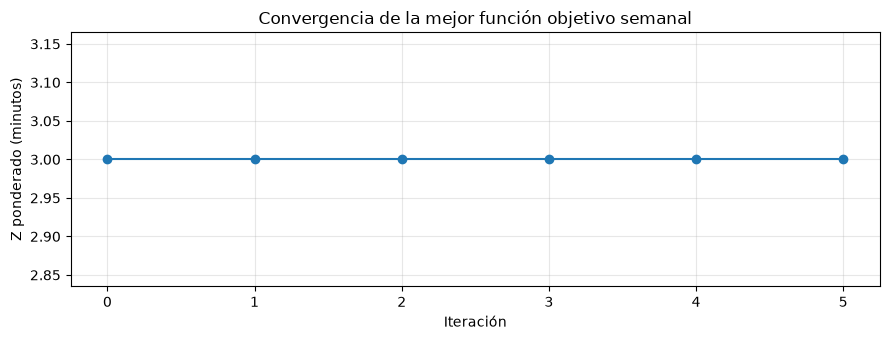

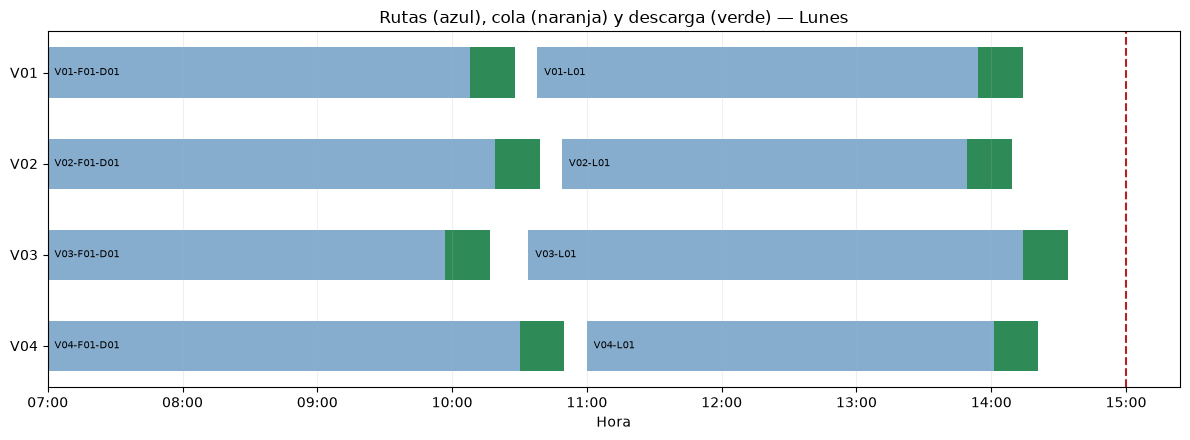

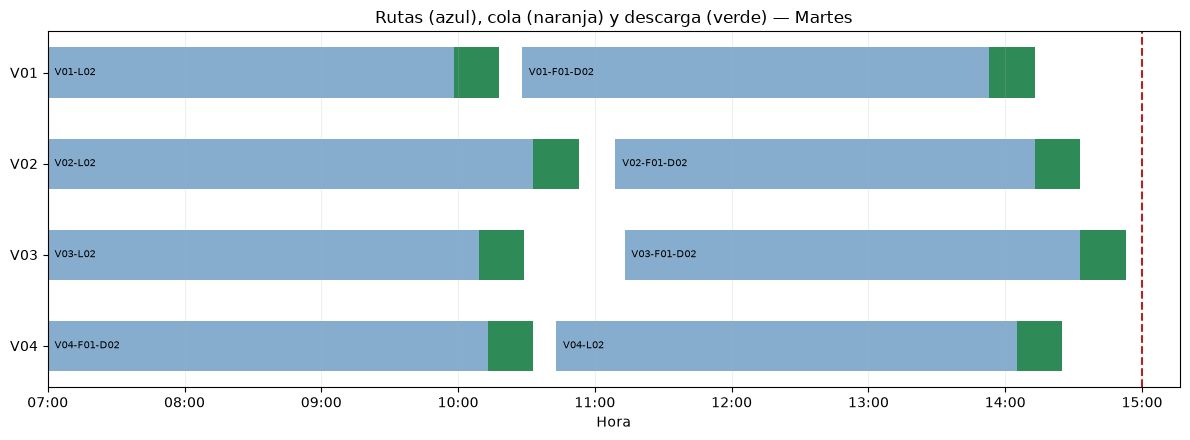

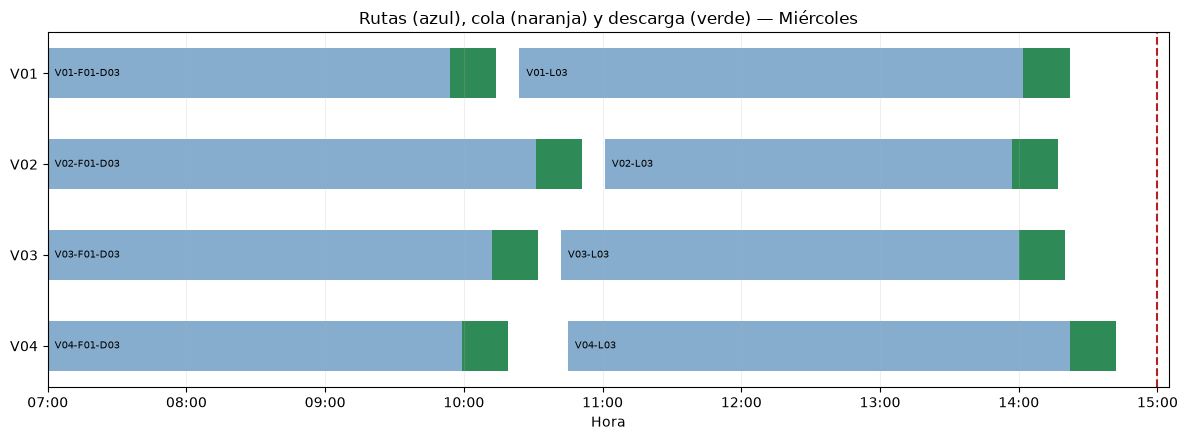

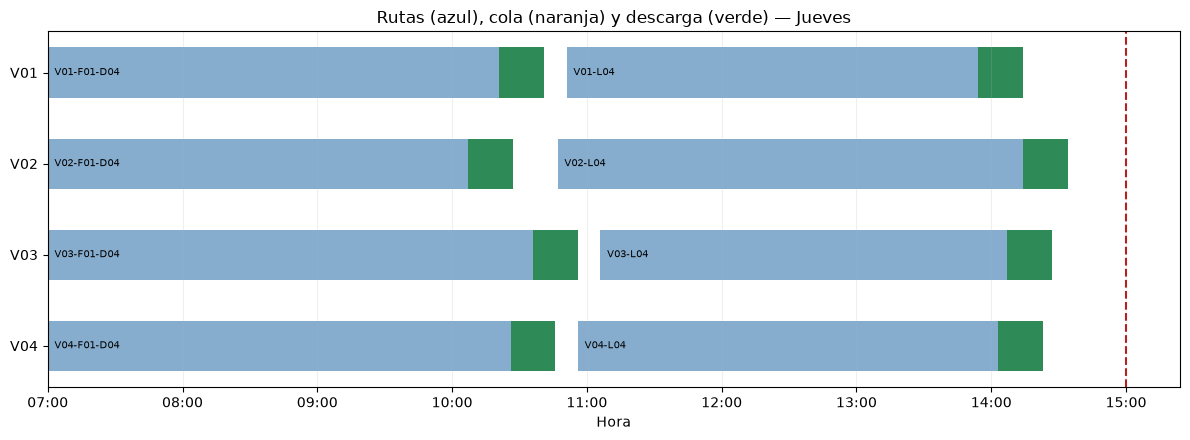

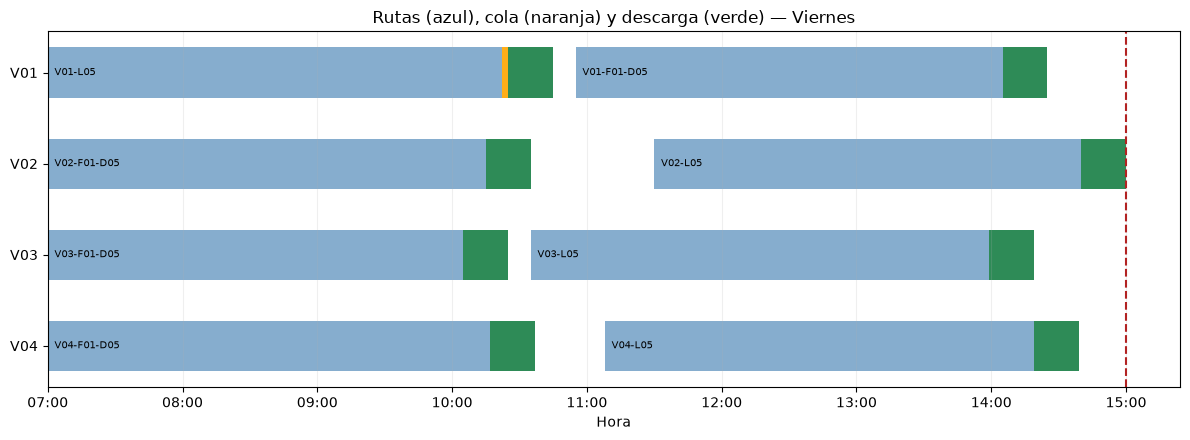

In [25]:
def hhmm(minutos):
    m = int(round(minutos))
    return f"{m//60:02d}:{m%60:02d}"

print("\nCONFIGURACIÓN SEMANAL PROPUESTA")
propuesta = mejor[["vehiculo", "ruta", "dia", "tipo", "duracion"]].copy()
propuesta["dia"] = pd.Categorical(propuesta.dia, DIAS, ordered=True)
propuesta = propuesta.sort_values(["dia", "vehiculo", "ruta"])
display(propuesta.reset_index(drop=True))

resumen = pd.DataFrame([dict(dia=d, estado=r["estado"], cola_min=r["cola"], extra_min=r["extra"], 
                             ocio_min=r["ocio"], objetivo=r["objetivo"]) for d, r in eval_mejor["diarios"].items()])
print("\nRESULTADOS DIARIOS")
display(resumen)
print("\nFUNCIONES OBJETIVO SEMANALES")
print(f"Z1 (espera en cola): {eval_mejor['cola']:.2f} minutos")
print(f"Z2 (tiempo extraordinario): {eval_mejor['extra']:.2f} minutos")
print(f"Indicador de ocio adicional: {eval_mejor['ocio']:.2f} minutos")
print(f"Z = {ALPHA} × Z1 + {BETA} × Z2 = {eval_mejor['objetivo']:.2f}")
print(f"Soluciones diarias diferentes evaluadas: {len(CACHE)}")

programaciones = [r["programacion"] for r in eval_mejor["diarios"].values() if r["programacion"] is not None and not r["programacion"].empty]
programacion = pd.concat(programaciones, ignore_index=True) if programaciones else pd.DataFrame()
if not programacion.empty:
    for campo in ["inicio", "llegada", "inicio_descarga", "fin_descarga"]:
        programacion[campo + "_hora"] = programacion[campo].map(hhmm)
    print("\nHORARIOS PROPUESTOS (PRIMERAS 25 OPERACIONES)")
    display(programacion[["dia", "vehiculo", "ruta", "inicio_hora", "llegada_hora", "inicio_descarga_hora", "fin_descarga_hora", "bahia", "cola", "ocio"]])

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(historial.iteracion, historial.mejor, marker="o")
ax.set(title="Convergencia de la mejor función objetivo semanal", xlabel="Iteración", ylabel="Z ponderado (minutos)")
ax.grid(alpha=.3); plt.tight_layout(); plt.show()

def diagrama_dia(dia="Lunes"):
    r = eval_mejor["diarios"][dia]
    df = r["programacion"]
    if df is None or df.empty:
        print("Sin programación factible para", dia)
        return
    vs = sorted(df.vehiculo.unique())
    fig, ax = plt.subplots(figsize=(12, 4.5))
    for _, fila in df.iterrows():
        y = vs.index(fila.vehiculo)
        # Segmento de recorrido, espera en cola y servicio de descarga.
        ax.barh(y, fila.llegada-fila.inicio, left=fila.inicio, height=.55, color="steelblue", alpha=.65)
        if fila.cola > .01:
            ax.barh(y, fila.cola, left=fila.llegada, height=.55, color="orange", alpha=.9)
        ax.barh(y, fila.fin_descarga-fila.inicio_descarga, left=fila.inicio_descarga, height=.55, color="seagreen")
        ax.text(fila.inicio+3, y, fila.ruta, va="center", fontsize=7)
    ax.axvline(HORA_FIN, color="firebrick", linestyle="--", label="Fin de jornada")
    ax.set_yticks(range(len(vs)), vs)
    ax.invert_yaxis()
    ax.set_xticks(np.arange(HORA_INICIO, max(HORA_FIN+60, df.fin_descarga.max()+30), 60))
    ax.set_xticklabels([hhmm(t) for t in ax.get_xticks()])
    ax.set(xlabel="Hora", title=f"Rutas (azul), cola (naranja) y descarga (verde) — {dia}")
    ax.grid(axis="x", alpha=.2)
    plt.tight_layout(); plt.show()

diagrama_dia("Lunes")
diagrama_dia("Martes")
diagrama_dia("Miércoles")
diagrama_dia("Jueves")
diagrama_dia("Viernes")


## 7. Verificación y exportación

La validación revisa horarios, intervalos entre rutas, bahías sin solapamiento, ventanas de asignación y consistencia del tiempo extraordinario. Los CSV se guardan en el directorio donde se ejecuta el notebook. **Nota:** no se obliga a FIFO en una cola física única; las bahías se reservan mediante una programación anticipada. Si se requiere FIFO estricto, habrá que agregar restricciones de orden de llegada o simular una disciplina de cola explícita.

In [26]:
def validar_solucion(configuracion, evaluacion, tolerancia=1e-3):
    assert configuracion.ruta.is_unique
    assert configuracion.apply(lambda r: r.dia in r.dias_permitidos, axis=1).all()
    fijas = configuracion.tipo.eq("Fija")
    assert (configuracion.loc[fijas, "dia"] == configuracion.loc[fijas, "dia_original"]).all()
    for dia, r in evaluacion["diarios"].items():
        df = r["programacion"]
        if df is None:
            raise AssertionError(f"Sin solución factible para {dia}")
        if df.empty:
            continue
        assert np.allclose(df.llegada, df.inicio + df.duracion, atol=tolerancia)
        assert np.allclose(df.fin_descarga, df.inicio_descarga+DURACION_DESCARGA, atol=tolerancia)
        assert np.allclose(df.cola, df.inicio_descarga-df.llegada, atol=tolerancia)
        for v, grupo in df.groupby("vehiculo"):
            orden = grupo.sort_values("inicio")
            assert abs(orden.inicio.iloc[0]-HORA_INICIO) < tolerancia
            assert (orden.fin_descarga.max() <= HORA_FIN+r["extra_por_vehiculo"][v]+tolerancia)
            for (_, i), (_, j) in zip(orden.iloc[:-1].iterrows(), orden.iloc[1:].iterrows()):
                assert j.inicio + tolerancia >= i.fin_descarga + INTERVALO_MINIMO
        for bahia, grupo in df.groupby("bahia"):
            orden = grupo.sort_values("inicio_descarga")
            for (_, i), (_, j) in zip(orden.iloc[:-1].iterrows(), orden.iloc[1:].iterrows()):
                assert j.inicio_descarga + tolerancia >= i.fin_descarga
    print("Validación de asignación y programación: correcta")

if np.isfinite(eval_mejor["objetivo"]):
    validar_solucion(mejor, eval_mejor)
    propuesta.to_csv("rutas_semanales_propuestas.csv", index=False, encoding="utf-8-sig")
    resumen.to_csv("indicadores_diarios.csv", index=False, encoding="utf-8-sig")
    historial.to_csv("convergencia.csv", index=False, encoding="utf-8-sig")
    if not programacion.empty:
        programacion.to_csv("programacion_detallada.csv", index=False, encoding="utf-8-sig")
    print("CSV exportados")
else:
    print("No se encontró una programación factible; aumente TIEMPO_MILP o MAX_EXTRA.")

Validación de asignación y programación: correcta
CSV exportados
